In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams["font.family"] = "Arial"
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from patsy import dmatrices

from additives_microbiota.plotting import process_string, pretty_var_names
from additives_microbiota.constants import ADDITIVE_VARS, MIXTURES
from additives_microbiota.regression_modeling import fit_regression_model, modeling_stat_tests, calculate_vif, forest_plot

### Loading Metadata

In [2]:
meta = pd.read_csv("../../data/metadata_files/meta_mixtures.csv", index_col=0)
print(meta.shape)

(975, 201)


## Regression Models

#### Running for all mixtures

In [3]:
# Note: Even adding fast_food_fg_eaten to the model doesn't change the results

demographic_vars = [
    "age",
    "bmi",
    "C(gender)",
    "HEI",
    "C(language, Treatment(reference='latin'))",
    "defecate_quantity_per_day",
    "C(urbanity, Treatment(reference='rural'))",
    "C(smoking, Treatment(reference='non-smoker'))",
    # "eaten_quantity_in_gram",
    "energy_kcal_eaten",
    "C(antibiotics_treatment)",
    "alcohol_eaten",
    "batch",
]

In [4]:
stats_mixtures, model, robust_model, clean_model = modeling_stat_tests(
    meta,
    MIXTURES,
    "shannon_entropy",
    demographic_vars=demographic_vars,
    bootstrap_var="Mixture3",
)

len(cooks): 940
len(high_infl): 41


In [5]:
print("bootstrap_ci", stats_mixtures["bootstrap_ci"])
print("heteroskedasticity_test", stats_mixtures["heteroskedasticity_test"])
print("vif_results", stats_mixtures["vif_results"])

bootstrap_ci (np.float64(-0.6880928499073014), np.float64(-0.05652509844811844))
heteroskedasticity_test {'Lagrange multiplier stat': np.float64(11.566503649736424), 'LM p-value': np.float64(0.9505886289040734), 'F-stat': np.float64(0.544596298224415), 'F p-value': np.float64(0.9525332842401445)}
vif_results                                              Variable       VIF
9                                 batch[T.batch_1599]  2.771627
3   C(urbanity, Treatment(reference='rural'))[T.ur...  2.709912
10                                batch[T.batch_2013]  2.704635
2   C(urbanity, Treatment(reference='rural'))[T.se...  2.659970
8                                 batch[T.batch_1205]  2.612716
11                                batch[T.batch_2718]  2.453662
7                                 batch[T.batch_0682]  2.453225
19                                  energy_kcal_eaten  1.351639
0                                   C(gender)[T.male]  1.332528
20                                      alcohol_ea

In [6]:
stats_mixtures["non_robust_model"]

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.209
Model:                            OLS   Adj. R-squared:                  0.191
Method:                 Least Squares   F-statistic:                     11.55
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.36e-34
Time:                        09:03:42   Log-Likelihood:                -633.90
No. Observations:                 940   AIC:                             1312.
Df Residuals:                     918   BIC:                             1418.
Df Model:                          21                                         
Covariance Type:            nonrobust                                         
===========================================================================================================================
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.9589      0.229     25.988      0.000       5.509       6.409
C(gender)[T.male]                                           0.0583      0.036      1.600      0.110      -0.013       0.130
C(language, Treatment(reference='latin'))[T.german]        -0.0986      0.035     -2.851      0.004      -0.166      -0.031
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0553      0.071     -0.777      0.438      -0.195       0.084
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1085      0.062     -1.761      0.079      -0.230       0.012
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1155      0.035     -3.344      0.001      -0.183      -0.048
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.2000      0.056     -3.546      0.000      -0.311      -0.089
C(antibiotics_treatment)[T.True]                           -0.1113      0.074     -1.495      0.135      -0.258       0.035
batch[T.batch_0682]                                         0.0555      0.063      0.884      0.377      -0.068       0.179
batch[T.batch_1205]                                         0.0788      0.065      1.213      0.225      -0.049       0.206
batch[T.batch_1599]                                        -0.1000      0.067     -1.495      0.135      -0.231       0.031
batch[T.batch_2013]                                        -0.0280      0.067     -0.420      0.675      -0.159       0.103
batch[T.batch_2718]                                        -0.2587      0.067     -3.848      0.000      -0.391      -0.127
Mixture1                                                   -0.1490      0.185     -0.806      0.421      -0.512       0.214
Mixture2                                                   -0.0967      0.109     -0.884      0.377      -0.311       0.118
Mixture3                                                   -0.3938      0.125     -3.154      0.002      -0.639      -0.149
age                                                         0.0077      0.001      5.468      0.000       0.005       0.010
bmi                                                        -0.0136      0.005     -3.020      0.003      -0.022      -0.005
HEI                                                         0.0113      0.002      4.626      0.000       0.007       0.016
defecate_quantity_per_day                                  -0.1210      0.022     -5.404      0.000      -0.165      -0.077
energy_kcal_eaten                                        2.847e-06   4.48e-05      0.064      0.949   -8.51e-05    9.08e-05
alcohol_eaten                                               0.0011      0.002      0.555      0.579      -0

In [7]:
stats_mixtures["robust_model"]

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.209
Model:                            OLS   Adj. R-squared:                  0.191
Method:                 Least Squares   F-statistic:                     11.30
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           8.70e-34
Time:                        09:03:43   Log-Likelihood:                -633.90
No. Observations:                 940   AIC:                             1312.
Df Residuals:                     918   BIC:                             1418.
Df Model:                          21                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.9589      0.224     26.645      0.000       5.521       6.397
C(gender)[T.male]                                           0.0583      0.036      1.601      0.109      -0.013       0.130
C(language, Treatment(reference='latin'))[T.german]        -0.0986      0.036     -2.772      0.006      -0.168      -0.029
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0553      0.066     -0.832      0.405      -0.185       0.075
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1085      0.056     -1.946      0.052      -0.218       0.001
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1155      0.035     -3.337      0.001      -0.183      -0.048
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.2000      0.058     -3.420      0.001      -0.315      -0.085
C(antibiotics_treatment)[T.True]                           -0.1113      0.068     -1.635      0.102      -0.245       0.022
batch[T.batch_0682]                                         0.0555      0.064      0.867      0.386      -0.070       0.181
batch[T.batch_1205]                                         0.0788      0.070      1.131      0.258      -0.058       0.215
batch[T.batch_1599]                                        -0.1000      0.069     -1.459      0.145      -0.234       0.034
batch[T.batch_2013]                                        -0.0280      0.068     -0.411      0.681      -0.162       0.106
batch[T.batch_2718]                                        -0.2587      0.068     -3.787      0.000      -0.393      -0.125
Mixture1                                                   -0.1490      0.227     -0.657      0.511      -0.594       0.296
Mixture2                                                   -0.0967      0.093     -1.040      0.298      -0.279       0.086
Mixture3                                                   -0.3938      0.231     -1.705      0.088      -0.846       0.059
age                                                         0.0077      0.001      5.336      0.000       0.005       0.010
bmi                                                        -0.0136      0.004     -3.056      0.002      -0.022      -0.005
HEI                                                         0.0113      0.002      4.645      0.000       0.007       0.016
defecate_quantity_per_day                                  -0.1210      0.023     -5.192      0.000      -0.167      -0.075
energy_kcal_eaten                                        2.847e-06   4.08e-05      0.070      0.944   -7.71e-05    8.28e-05
alcohol_eaten                                               0.0011      0.002      0.575      0.565      -0

In [8]:
stats_mixtures["removed_influential_rows_robust_model"]

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.282
Model:                            OLS   Adj. R-squared:                  0.265
Method:                 Least Squares   F-statistic:                     19.33
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           8.45e-59
Time:                        09:03:56   Log-Likelihood:                -473.10
No. Observations:                 899   AIC:                             990.2
Df Residuals:                     877   BIC:                             1096.
Df Model:                          21                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.9228      0.193     30.617      0.000       5.544       6.302
C(gender)[T.male]                                           0.0753      0.032      2.344      0.019       0.012       0.138
C(language, Treatment(reference='latin'))[T.german]        -0.0956      0.031     -3.090      0.002      -0.156      -0.035
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0581      0.060     -0.970      0.332      -0.175       0.059
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.0941      0.049     -1.906      0.057      -0.191       0.003
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1256      0.030     -4.202      0.000      -0.184      -0.067
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.2205      0.051     -4.309      0.000      -0.321      -0.120
C(antibiotics_treatment)[T.True]                           -0.0869      0.052     -1.678      0.093      -0.188       0.015
batch[T.batch_0682]                                         0.0614      0.056      1.099      0.272      -0.048       0.171
batch[T.batch_1205]                                         0.0744      0.057      1.311      0.190      -0.037       0.186
batch[T.batch_1599]                                        -0.1181      0.058     -2.030      0.042      -0.232      -0.004
batch[T.batch_2013]                                        -0.0306      0.059     -0.520      0.603      -0.146       0.085
batch[T.batch_2718]                                        -0.2930      0.060     -4.888      0.000      -0.410      -0.176
Mixture1                                                    0.0904      0.151      0.597      0.550      -0.206       0.387
Mixture2                                                   -0.0308      0.092     -0.335      0.738      -0.211       0.150
Mixture3                                                   -0.5575      0.104     -5.344      0.000      -0.762      -0.353
age                                                         0.0092      0.001      7.516      0.000       0.007       0.012
bmi                                                        -0.0170      0.004     -4.281      0.000      -0.025      -0.009
HEI                                                         0.0118      0.002      5.550      0.000       0.008       0.016
defecate_quantity_per_day                                  -0.1257      0.020     -6.442      0.000      -0.164      -0.087
energy_kcal_eaten                                        1.485e-05   3.79e-05      0.392      0.695   -5.95e-05    8.92e-05
alcohol_eaten                                               0.0017      0.002      1.105      0.269      -0

In [9]:
with open(
    "../outputs/supplementary_files/model_summary_mixtures_standard_OLS.txt",
    "w",
) as f:
    f.write(stats_mixtures["non_robust_model"].as_text())

## Forest Plot

This plot is for the clean model, which refers to the model with the influential points removed


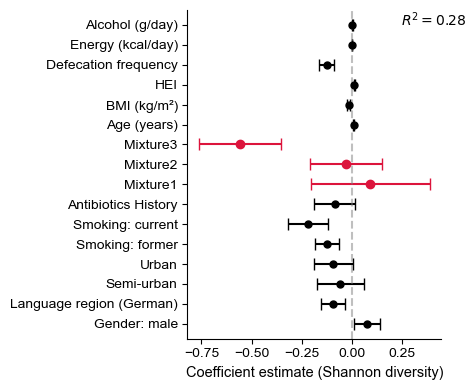

In [10]:
fig, ax = forest_plot(
    clean_model,
    title="",
    figsize=(5, 4),
    r2_annot_loc=(1.1, 1.0),
    pretty_var_names=pretty_var_names,
    highlight_vars=MIXTURES,
    base_color="black",
    highlight_color="crimson",
)
sns.despine()

print(
    "This plot is for the clean model, which refers to the model with the influential points removed"
)

# plt.savefig(
#     "../figures/mixtures/forest_plot_mixtures_removedInfluentialPoints.png",
#     dpi=300,
#     bbox_inches="tight",
# )

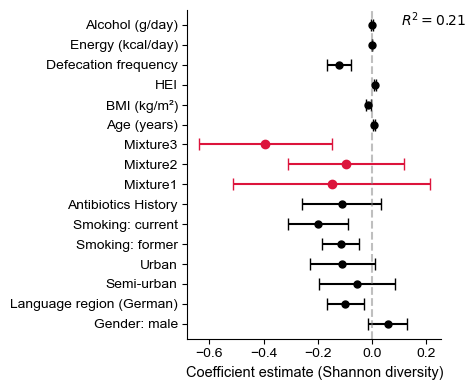

In [11]:
fig, ax = forest_plot(
    model,
    title="",
    figsize=(5, 4),
    r2_annot_loc=(1.1, 1.0),
    pretty_var_names=pretty_var_names,
    highlight_vars=MIXTURES,
    base_color="black",
    highlight_color="crimson",
)
sns.despine()

plt.savefig(
    "../figures/mixtures/forest_plot_mixtures.png", dpi=300, bbox_inches="tight"
)

In [12]:
meta["Mixture3"].describe()

count    975.000000
mean       0.025824
std        0.130003
min        0.000000
25%        0.000000
50%        0.000124
75%        0.011022
max        2.271186
Name: Mixture3, dtype: float64

## Doing Bootstrapping, Quantile Regression, Permutation Test
### (Other modeling tests to ascertain the robustness of the results for the mixtures)


In [13]:
def fit_rlm_with_bootstrap_se(
    data, additives_cols, dependent_var, demographic_vars=None, n_boot=1000
):
    # build formula
    formula = f"{dependent_var} ~ " + " + ".join(additives_cols)
    if demographic_vars:
        formula += " + " + " + ".join(demographic_vars)

    # fit original RLM
    orig_rlm = smf.rlm(formula, data=data, M=sm.robust.norms.HuberT()).fit()

    # bootstrap
    boot_params = []
    for _ in range(n_boot):
        bs = data.sample(frac=1, replace=True)
        m = smf.rlm(formula, data=bs, M=sm.robust.norms.HuberT()).fit()
        boot_params.append(m.params)

    boot_df = pd.DataFrame(boot_params)
    orig_rlm.bse_boot = boot_df.std()  # attach bootstrap SEs

    return orig_rlm


rlm_model = fit_rlm_with_bootstrap_se(
    meta, MIXTURES, "shannon_entropy", demographic_vars
)
print(rlm_model.summary())
print("Bootstrapped SEs:\n", rlm_model.bse_boot)


with open(
    "../outputs/supplementary_files/model_summary_mixtures_robustlm_with_bootstrap.txt",
    "w",
) as f:
    f.write(rlm_model.summary().as_text())

                    Robust linear Model Regression Results                    
Dep. Variable:        shannon_entropy   No. Observations:                  940
Model:                            RLM   Df Residuals:                      918
Method:                          IRLS   Df Model:                           21
Norm:                          HuberT                                         
Scale Est.:                       mad                                         
Cov Type:                          H1                                         
Date:                Wed, 11 Mar 2026                                         
Time:                        09:04:54                                         
No. Iterations:                    39                                         
                                                              coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------

In [14]:
def fit_quantile_regression(
    data, additives_cols, dependent_var, demographic_vars=None, q=0.5
):
    formula = f"{dependent_var} ~ " + " + ".join(additives_cols)
    if demographic_vars:
        formula += " + " + " + ".join(demographic_vars)

    qr = smf.quantreg(formula, data).fit(q=q)
    return qr


qr50 = fit_quantile_regression(
    meta, MIXTURES, "shannon_entropy", demographic_vars, q=0.5
)
print(qr50.summary())

                         QuantReg Regression Results                          
Dep. Variable:        shannon_entropy   Pseudo R-squared:               0.1317
Model:                       QuantReg   Bandwidth:                      0.2301
Method:                 Least Squares   Sparsity:                        1.098
Date:                Wed, 11 Mar 2026   No. Observations:                  940
Time:                        09:04:54   Df Residuals:                      918
                                        Df Model:                           21
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   6.0757      0.262     23.192      0.000       5.562       6.590
C(gender)[T.male]                                           0.0394      0.0

In [15]:
def permutation_test_coef(
    data,
    additives_cols,
    dependent_var,
    demographic_vars=None,
    var="Mixture3",
    n_perm=2000,
):
    # build formula
    formula = f"{dependent_var} ~ " + " + ".join(additives_cols)
    if demographic_vars:
        formula += " + " + " + ".join(demographic_vars)

    # observed coefficient
    obs_coef = smf.ols(formula, data).fit().params[var]

    perm_coefs = []
    for _ in range(n_perm):
        permuted = data.copy()
        permuted[var] = np.random.permutation(permuted[var].values)
        coef = smf.ols(formula, permuted).fit().params[var]
        perm_coefs.append(coef)

    perm_coefs = np.array(perm_coefs)
    p_value = np.mean(np.abs(perm_coefs) >= np.abs(obs_coef))
    return obs_coef, p_value, perm_coefs


obs, p_val, null_dist = permutation_test_coef(
    meta, MIXTURES, "shannon_entropy", demographic_vars
)
print(f"Observed Mixture3 coef = {obs:.3f}, permutation p = {p_val:.3f}")

Observed Mixture3 coef = -0.394, permutation p = 0.005


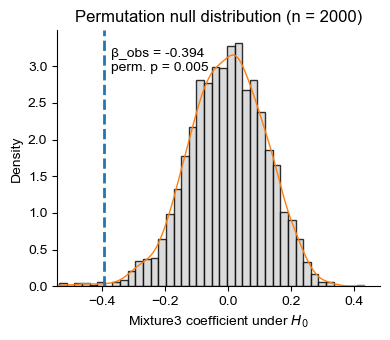

In [16]:
from scipy import stats

fig, ax = plt.subplots(figsize=(4, 3.5))

# histogram
ax.hist(
    null_dist,
    bins=40,
    density=True,
    facecolor="lightgrey",
    edgecolor="black",
    alpha=0.8,
)

# KDE overlay
kde_x = np.linspace(null_dist.min(), null_dist.max(), 400)
kde_y = stats.gaussian_kde(null_dist)(kde_x)
ax.plot(kde_x, kde_y, linewidth=1)

# observed coefficient
ax.axvline(obs, color="tab:blue", linestyle="--", linewidth=2)
ax.text(
    obs + 0.02,
    kde_y.max() + 0.1,
    f"β_obs = {obs:.3f}\nperm. p = {p_val:.3f}",
    ha="left",
    va="top",
)

# axis labels & limits
ax.set_xlabel("Mixture3 coefficient under $H_0$")
ax.set_ylabel("Density")
ax.set_xlim(obs - 0.15, null_dist.max() + 0.05)
ax.set_title("Permutation null distribution (n = 2000)")

fig.tight_layout()
sns.despine()
plt.savefig(
    "../figures/mixtures/mixtures_permutation_test.png",
    dpi=300,
    bbox_inches="tight",
)

## Models on Additive Category

In [17]:
all_additive_diversity_model = fit_regression_model(
    meta,
    ADDITIVE_VARS,
    demographic_vars=demographic_vars,
    dependent_var="shannon_entropy",
    robust_regression=False,
    do_robust_se=False,
)

all_additive_diversity_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.189
Method:                 Least Squares   F-statistic:                     9.773
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           5.90e-33
Time:                        09:05:23   Log-Likelihood:                -632.71
No. Observations:                 940   AIC:                             1317.
Df Residuals:                     914   BIC:                             1443.
Df Model:                          25                                         
Covariance Type:            nonrobust                                         
===========================================================================================================================
                                                              coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.9520      0.231     25.780      0.000       5.499       6.405
C(gender)[T.male]                                           0.0591      0.037      1.615      0.107      -0.013       0.131
C(language, Treatment(reference='latin'))[T.german]        -0.0984      0.035     -2.832      0.005      -0.167      -0.030
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0559      0.071     -0.785      0.433      -0.195       0.084
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1031      0.062     -1.671      0.095      -0.224       0.018
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1121      0.035     -3.224      0.001      -0.180      -0.044
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.1952      0.057     -3.444      0.001      -0.306      -0.084
C(antibiotics_treatment)[T.True]                           -0.1186      0.075     -1.589      0.112      -0.265       0.028
batch[T.batch_0682]                                         0.0481      0.063      0.762      0.446      -0.076       0.172
batch[T.batch_1205]                                         0.0701      0.065      1.074      0.283      -0.058       0.198
batch[T.batch_1599]                                        -0.1105      0.067     -1.639      0.102      -0.243       0.022
batch[T.batch_2013]                                        -0.0374      0.067     -0.556      0.578      -0.169       0.095
batch[T.batch_2718]                                        -0.2714      0.068     -4.010      0.000      -0.404      -0.139
thickeners_stabilizers_emulsifiers_gelling_agents          -0.0013      0.020     -0.066      0.947      -0.041       0.038
sweeteners_glazing_agents                                  -0.0331      0.014     -2.295      0.022      -0.061      -0.005
preservatives_antioxidants                                 -0.0634      0.035     -1.811      0.071      -0.132       0.005
ph_regulators_anti_caking_leavening_agents                 -0.0046      0.017     -0.268      0.789      -0.038       0.029
other_additives                                             0.0870      0.235      0.371      0.711      -0.374       0.548
flavor_enhancers                                            0.0392      0.127      0.308      0.758      -0.210       0.289
colorants                                                   0.0398      0.046      0.856      0.392      -0.051       0.131
age                                                         0.0075      0.001      5.353      0.000       0.005       0.010
bmi                                                        -0.0134      0.005     -2.974      0.003      -0

In [18]:
print(calculate_vif(all_additive_diversity_model, meta))

                                             Variable       VIF
9                                 batch[T.batch_1599]  2.811677
10                                batch[T.batch_2013]  2.732974
3   C(urbanity, Treatment(reference='rural'))[T.ur...  2.707505
2   C(urbanity, Treatment(reference='rural'))[T.se...  2.651385
8                                 batch[T.batch_1205]  2.629363
11                                batch[T.batch_2718]  2.481967
7                                 batch[T.batch_0682]  2.467169
18                                          colorants  2.317887
13                          sweeteners_glazing_agents  2.133852
15         ph_regulators_anti_caking_leavening_agents  2.019495
12  thickeners_stabilizers_emulsifiers_gelling_agents  1.654172
14                         preservatives_antioxidants  1.398543
23                                  energy_kcal_eaten  1.346997
0                                   C(gender)[T.male]  1.340822
24                                      

In [19]:
for additive in ADDITIVE_VARS:
    individual_additive_diversity_model = fit_regression_model(
        meta,
        [additive],
        demographic_vars=demographic_vars,
        dependent_var="shannon_entropy",
        robust_regression=False,
        do_robust_se=False,
    )
    additive_pval = individual_additive_diversity_model.pvalues[additive]
    additive_effect = individual_additive_diversity_model.params[additive]
    if additive_pval < 0.05:
        print(additive, additive_pval, additive_effect)

sweeteners_glazing_agents 0.0011319396340456526 -0.03279139394205797
preservatives_antioxidants 0.004838942715631789 -0.08638298123430124
ph_regulators_anti_caking_leavening_agents 0.043817477534220765 -0.026309123323502565


### Running for total_additive_intake 

In [20]:
total_additive_intake_model = fit_regression_model(
    meta,
    ["total_additive_intake"],
    demographic_vars=demographic_vars,
    dependent_var="shannon_entropy",
    robust_regression=False,
    do_robust_se=True,
)
total_additive_intake_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.206
Model:                            OLS   Adj. R-squared:                  0.190
Method:                 Least Squares   F-statistic:                     12.48
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           9.51e-35
Time:                        09:05:24   Log-Likelihood:                -635.38
No. Observations:                 940   AIC:                             1311.
Df Residuals:                     920   BIC:                             1408.
Df Model:                          19                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   6.0103      0.224     26.823      0.000       5.571       6.449
C(gender)[T.male]                                           0.0603      0.036      1.657      0.097      -0.011       0.132
C(language, Treatment(reference='latin'))[T.german]        -0.0993      0.035     -2.804      0.005      -0.169      -0.030
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0652      0.067     -0.978      0.328      -0.196       0.066
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1125      0.055     -2.044      0.041      -0.220      -0.005
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1119      0.034     -3.256      0.001      -0.179      -0.045
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.1986      0.058     -3.436      0.001      -0.312      -0.085
C(antibiotics_treatment)[T.True]                           -0.1116      0.068     -1.638      0.101      -0.245       0.022
batch[T.batch_0682]                                         0.0571      0.063      0.904      0.366      -0.067       0.181
batch[T.batch_1205]                                         0.0758      0.068      1.108      0.268      -0.058       0.210
batch[T.batch_1599]                                        -0.0946      0.068     -1.402      0.161      -0.227       0.038
batch[T.batch_2013]                                        -0.0279      0.067     -0.414      0.679      -0.160       0.104
batch[T.batch_2718]                                        -0.2574      0.068     -3.808      0.000      -0.390      -0.125
total_additive_intake                                      -0.0137      0.006     -2.433      0.015      -0.025      -0.003
age                                                         0.0075      0.001      5.237      0.000       0.005       0.010
bmi                                                        -0.0134      0.004     -2.989      0.003      -0.022      -0.005
HEI                                                         0.0105      0.002      4.311      0.000       0.006       0.015
defecate_quantity_per_day                                  -0.1209      0.023     -5.250      0.000      -0.166      -0.076
energy_kcal_eaten                                        1.302e-05   4.05e-05      0.322      0.748   -6.63e-05    9.23e-05
alcohol_eaten                                               0.0008      0.002      0.449      0.653      -0.003       0.004
==============================================================================
Omnibus:                       71.817   Durbin-Watson:                   1.987
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              10

### Running for sweeteners_glazing_agents

In [21]:
sweeteners_glazing_agents_model = fit_regression_model(
    meta,
    ["sweeteners_glazing_agents"],
    demographic_vars=demographic_vars,
    dependent_var="shannon_entropy",
    # robust=True,
    robust_regression=False,
    do_robust_se=True,
)

sweeteners_glazing_agents_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.207
Model:                            OLS   Adj. R-squared:                  0.191
Method:                 Least Squares   F-statistic:                     12.38
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           1.86e-34
Time:                        09:05:24   Log-Likelihood:                -635.06
No. Observations:                 940   AIC:                             1310.
Df Residuals:                     920   BIC:                             1407.
Df Model:                          19                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.9456      0.221     26.854      0.000       5.512       6.380
C(gender)[T.male]                                           0.0600      0.036      1.648      0.099      -0.011       0.131
C(language, Treatment(reference='latin'))[T.german]        -0.0976      0.035     -2.766      0.006      -0.167      -0.028
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0571      0.066     -0.860      0.390      -0.187       0.073
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1090      0.055     -1.978      0.048      -0.217      -0.001
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1159      0.034     -3.374      0.001      -0.183      -0.049
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.1978      0.058     -3.400      0.001      -0.312      -0.084
C(antibiotics_treatment)[T.True]                           -0.1115      0.068     -1.644      0.100      -0.244       0.021
batch[T.batch_0682]                                         0.0534      0.064      0.839      0.401      -0.071       0.178
batch[T.batch_1205]                                         0.0733      0.069      1.064      0.287      -0.062       0.208
batch[T.batch_1599]                                        -0.1044      0.068     -1.544      0.123      -0.237       0.028
batch[T.batch_2013]                                        -0.0303      0.068     -0.445      0.656      -0.163       0.103
batch[T.batch_2718]                                        -0.2589      0.068     -3.800      0.000      -0.392      -0.125
sweeteners_glazing_agents                                  -0.0328      0.015     -2.119      0.034      -0.063      -0.002
age                                                         0.0076      0.001      5.321      0.000       0.005       0.010
bmi                                                        -0.0135      0.004     -3.058      0.002      -0.022      -0.005
HEI                                                         0.0117      0.002      4.827      0.000       0.007       0.016
defecate_quantity_per_day                                  -0.1215      0.023     -5.271      0.000      -0.167      -0.076
energy_kcal_eaten                                       -4.752e-06   4.02e-05     -0.118      0.906   -8.36e-05    7.41e-05
alcohol_eaten                                               0.0012      0.002      0.649      0.516      -0.002       0.005
==============================================================================
Omnibus:                       72.291   Durbin-Watson:                   1.986
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              10

In [ ]:
# sweeteners_glazing_agents_model_cohort_b = fit_regression_model(
#     meta[meta["cohort"] == "cohort_b"],
#     ["sweeteners_glazing_agents"],
#     demographic_vars=demographic_vars,
#     dependent_var="shannon_entropy",
#     # robust=True,
#     robust_regression=False,
#     do_robust_se=True,
# )

# sweeteners_glazing_agents_model_cohort_b.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.225
Model:                            OLS   Adj. R-squared:                  0.206
Method:                 Least Squares   F-statistic:                     11.83
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           3.88e-32
Time:                        09:06:07   Log-Likelihood:                -536.82
No. Observations:                 805   AIC:                             1114.
Df Residuals:                     785   BIC:                             1207.
Df Model:                          19                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   6.0129      0.238     25.274      0.000       5.547       6.479
C(gender)[T.male]                                           0.0733      0.038      1.922      0.055      -0.001       0.148
C(language, Treatment(reference='latin'))[T.german]        -0.1012      0.038     -2.658      0.008      -0.176      -0.027
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.1175      0.071     -1.658      0.097      -0.256       0.021
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1560      0.059     -2.640      0.008      -0.272      -0.040
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1343      0.037     -3.654      0.000      -0.206      -0.062
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.2206      0.065     -3.390      0.001      -0.348      -0.093
C(antibiotics_treatment)[T.True]                           -0.1008      0.079     -1.278      0.201      -0.255       0.054
batch[T.batch_0682]                                         0.0488      0.069      0.703      0.482      -0.087       0.185
batch[T.batch_1205]                                         0.0809      0.075      1.082      0.279      -0.066       0.228
batch[T.batch_1599]                                        -0.1298      0.074     -1.761      0.078      -0.274       0.015
batch[T.batch_2013]                                        -0.0411      0.074     -0.554      0.579      -0.186       0.104
batch[T.batch_2718]                                        -0.2519      0.073     -3.447      0.001      -0.395      -0.109
sweeteners_glazing_agents                                  -0.0316      0.016     -1.992      0.046      -0.063      -0.001
age                                                         0.0078      0.001      5.366      0.000       0.005       0.011
bmi                                                        -0.0155      0.005     -3.096      0.002      -0.025      -0.006
HEI                                                         0.0116      0.003      4.628      0.000       0.007       0.017
defecate_quantity_per_day                                  -0.1130      0.025     -4.530      0.000      -0.162      -0.064
energy_kcal_eaten                                       -7.922e-06   4.22e-05     -0.188      0.851   -9.06e-05    7.48e-05
alcohol_eaten                                               0.0026      0.002      1.437      0.151      -0.001       0.006
==============================================================================
Omnibus:                       63.325   Durbin-Watson:                   1.984
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               9

~/miniconda3/envs/additives/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


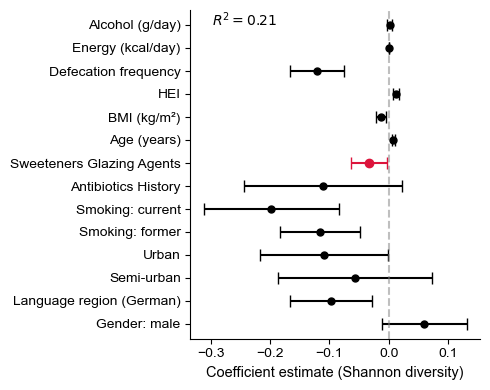

In [23]:
fig, ax = forest_plot(
    sweeteners_glazing_agents_model,
    # features=MIXTURES + demographic_vars,
    title="",
    figsize=(5, 4),
    pretty_var_names=pretty_var_names,
    highlight_vars=["sweeteners_glazing_agents"],
    base_color="black",
    highlight_color="crimson",
    r2_annot_loc=(0.3, 1.0),
)
sns.despine()

plt.savefig(
    "../figures/additive_descriptive/additive_effects_modeling/forest_plot_sweeteners_glazing_agents.png",
    dpi=300,
    bbox_inches="tight",
)

### Running for preservatives_antioxidants

In [24]:
preservatives_antioxidants_model = fit_regression_model(
    meta,
    ["preservatives_antioxidants"],
    demographic_vars=demographic_vars,
    dependent_var="shannon_entropy",
    # robust=True,
    robust_regression=False,
    do_robust_se=True,
)
preservatives_antioxidants_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:        shannon_entropy   R-squared:                       0.205
Model:                            OLS   Adj. R-squared:                  0.188
Method:                 Least Squares   F-statistic:                     12.93
Date:                Wed, 11 Mar 2026   Prob (F-statistic):           3.91e-36
Time:                        09:05:24   Log-Likelihood:                -636.42
No. Observations:                 940   AIC:                             1313.
Df Residuals:                     920   BIC:                             1410.
Df Model:                          19                                         
Covariance Type:                  HC3                                         
===========================================================================================================================
                                                              coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------
Intercept                                                   5.9860      0.223     26.863      0.000       5.549       6.423
C(gender)[T.male]                                           0.0653      0.036      1.803      0.071      -0.006       0.136
C(language, Treatment(reference='latin'))[T.german]        -0.1032      0.035     -2.912      0.004      -0.173      -0.034
C(urbanity, Treatment(reference='rural'))[T.semi_urban]    -0.0586      0.066     -0.890      0.373      -0.188       0.070
C(urbanity, Treatment(reference='rural'))[T.urban]         -0.1023      0.054     -1.893      0.058      -0.208       0.004
C(smoking, Treatment(reference='non-smoker'))[T.former]    -0.1110      0.034     -3.216      0.001      -0.179      -0.043
C(smoking, Treatment(reference='non-smoker'))[T.smoker]    -0.1942      0.057     -3.399      0.001      -0.306      -0.082
C(antibiotics_treatment)[T.True]                           -0.1213      0.069     -1.765      0.078      -0.256       0.013
batch[T.batch_0682]                                         0.0430      0.063      0.684      0.494      -0.080       0.166
batch[T.batch_1205]                                         0.0622      0.069      0.905      0.365      -0.072       0.197
batch[T.batch_1599]                                        -0.1098      0.067     -1.640      0.101      -0.241       0.021
batch[T.batch_2013]                                        -0.0388      0.068     -0.574      0.566      -0.171       0.094
batch[T.batch_2718]                                        -0.2726      0.068     -4.010      0.000      -0.406      -0.139
preservatives_antioxidants                                 -0.0864      0.031     -2.776      0.005      -0.147      -0.025
age                                                         0.0075      0.001      5.206      0.000       0.005       0.010
bmi                                                        -0.0141      0.004     -3.185      0.001      -0.023      -0.005
HEI                                                         0.0110      0.002      4.563      0.000       0.006       0.016
defecate_quantity_per_day                                  -0.1181      0.023     -5.095      0.000      -0.163      -0.073
energy_kcal_eaten                                        6.736e-06   4.03e-05      0.167      0.867   -7.23e-05    8.57e-05
alcohol_eaten                                               0.0012      0.002      0.636      0.525      -0.002       0.005
==============================================================================
Omnibus:                       79.768   Durbin-Watson:                   1.978
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              12

In [30]:
# preservatives_antioxidants_model_cohort_b = fit_regression_model(
#     meta[meta["cohort"] == "cohort_b"],
#     ["preservatives_antioxidants"],
#     demographic_vars=demographic_vars,
#     dependent_var="shannon_entropy",
#     # robust=True,
#     robust_regression=False,
#     do_robust_se=True,
# )
# preservatives_antioxidants_model_cohort_b.summary()

~/miniconda3/envs/additives/lib/python3.12/site-packages/matplotlib/cbook.py:1719: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return math.isfinite(val)


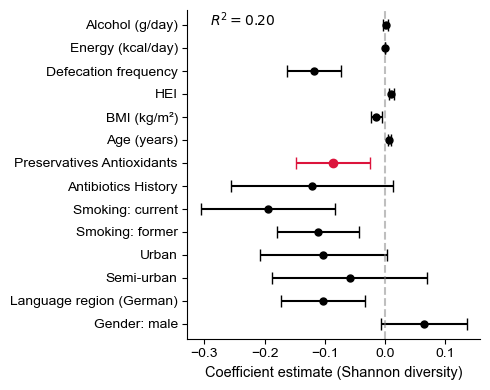

In [25]:
fig, ax = forest_plot(
    preservatives_antioxidants_model,
    # features=MIXTURES + demographic_vars,
    title="",
    figsize=(5, 4),
    pretty_var_names=pretty_var_names,
    highlight_vars=["preservatives_antioxidants"],
    base_color="black",
    highlight_color="crimson",
    r2_annot_loc=(0.3, 1.0),
)
sns.despine()

plt.savefig(
    "../figures/additive_descriptive/additive_effects_modeling/forest_plot_preservatives_antioxidants.png",
    dpi=300,
    bbox_inches="tight",
)

### Saving modeling summaries for single additive models

In [26]:
with open(
    "../outputs/supplementary_files/model_summary_sweeteners_glazing_agents.txt",
    "w",
) as f:
    f.write(sweeteners_glazing_agents_model.summary().as_text())

with open(
    "../outputs/supplementary_files/model_summary_preservatives_antioxidants.txt",
    "w",
) as f:
    f.write(preservatives_antioxidants_model.summary().as_text())